# Deteccion, Clasificacion y Cuantificacion de Monedas con YOLO11

### Taller de Vision Artificial - Pipeline end-to-end (Google Colab)

**Objetivo:** construir un sistema de vision artificial capaz de **reconocer, clasificar y cuantificar** el valor monetario de las monedas presentes en una escena, mediante *transfer learning* sobre **YOLO11** entrenado con un **dataset propio**.

**Base de referencia:** [Ultralytics Tutorial Notebook](https://colab.research.google.com/github/ultralytics/ultralytics/blob/main/examples/tutorial.ipynb)

---

**Contenido del notebook**

1. Configuracion del entorno (GPU + dependencias)
2. Dataset propio: protocolo de captura, iluminacion y anotacion
3. Analisis exploratorio del dataset (EDA)
4. Entrenamiento con Transfer Learning y justificacion de hiperparametros
5. Validacion y metricas (loss, mAP, matriz de confusion)
6. Inferencia + **logica de cuantificacion monetaria**
7. **Bonus (+1):** Edge Computing - exportacion e inferencia local
8. **Bonus (+1):** Integracion de papel moneda (billetes)
9. Conclusiones tecnicas (falsos positivos/negativos y oclusion)


## 1. Configuracion del entorno

Antes de ejecutar: `Entorno de ejecucion > Cambiar tipo de entorno de ejecucion > T4 GPU`.

Verificamos el hardware disponible y luego instalamos las dependencias necesarias:

- `ultralytics`: framework de entrenamiento/inferencia (YOLO11).
- `roboflow`: cliente para descargar el dataset anotado en formato YOLO.


In [1]:
# Hardware check
!nvidia-smi


Mon Oct 19 04:25:32 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   43C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
# Install dependencies
!pip install -q --upgrade ultralytics roboflow


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 460.6 kB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 4.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 373.9/373.9 kB 27.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 29.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.4/58.4 kB 3.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.6/97.6 kB 8.9 MB/s eta 0:00:00


In [3]:
import os
import random
import shutil
from collections import Counter
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torchvision
import yaml
from IPython.display import display
from PIL import Image as PILImage

from ultralytics import YOLO

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

DEVICE = 0 if torch.cuda.is_available() else 'cpu'
print(f'Python       : {os.sys.version.split()[0]}')
print(f'torch        : {torch.__version__}')
print(f'torchvision  : {torchvision.__version__}')
print(f'CUDA available: {torch.cuda.is_available()}')
if torch.cuda.is_available():
    print(f'GPU          : {torch.cuda.get_device_name(0)}')
print(f'Device       : {DEVICE}')


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Python       : 3.13.15
torch        : 2.11.0+cu130
torchvision  : 0.26.0+cu130
CUDA available: True
GPU          : Tesla T4
Device       : 0


## 2. Dataset propio: captura, iluminacion y anotacion

### 2.1 Protocolo de captura (Custom Dataset)

Se recopilaron monedas de distintas denominaciones y se fotografiaron con la camara del dispositivo movil sobre una **superficie homogenea** (fondo mate, sin texturas). Se cubrieron tres variaciones espaciales obligatorias:

| Variacion | Descripcion | Proposito |
|---|---|---|
| Aislada | Una sola moneda centrada | Clase limpia, base de *features* |
| Agrupada | Varias monedas separadas en la misma escena | Multi-instancia y distintos tamanos |
| Oclusion parcial | Monedas tocandose / solapandose | Robustez ante bordes compartidos |

### 2.2 Ingenieria de iluminacion (experimentacion optica)

El metal es **altamente reflectivo**, por lo que la iluminacion es una variable critica. Se compararon empiricamente dos regimenes:

- **Luz ambiente difusa:** genera reflejos planos; el relieve (grabados, canto, numerales) se pierde y las monedas claras/plateadas se confunden con el fondo.
- **Luz direccional (flash o fuente externa lateral):** produce sombras internas que **resaltan el relieve y las caracteristicas topologicas**, mejorando la *feature extraction* de la red. Contrapartida: puede introducir *hotspots* especulares.

**Conclusion operativa:** se capturo la mayor parte del dataset con **flash / luz direccional controlada** y una fraccion menor con luz difusa, de forma que el modelo aprenda a ser robusto frente a la reflectividad del metal y no dependa de una unica condicion de iluminacion.

### 2.3 Anotacion

Se trazaron *bounding boxes* alrededor de cada moneda (Roboflow / CVAT / LabelImg) asignando la clase segun el **valor nominal** de la divisa:

`coin_50`, `coin_100`, `coin_200`, `coin_500`, `coin_1000` (pesos colombianos, COP).

El dataset se exporto en formato **YOLO** (`images/` + `labels/` con `.txt` normalizados `class cx cy w h`), compatible 100% con YOLO11.

> **Preparacion del dataset en Roboflow:** generar versiones con *augmentation* (flip horizontal/vertical, rotacion, cambios de brillo/exposicion y ruido) para simular variaciones de iluminacion y angulo. Exportar como **YOLOv8/YOLO11 PyTorch**.


In [4]:
# Download the annotated dataset from Roboflow (YOLO format)
from roboflow import Roboflow

RF_API_KEY = 'suLySbTG15we3QiM5ACj'
RF_WORKSPACE = 'jhonns-workspace-aebuy'
RF_PROJECT = 'deteccion_divisas'
RF_VERSION = 1

rf = Roboflow(api_key=RF_API_KEY)
project = rf.workspace(RF_WORKSPACE).project(RF_PROJECT)

# 'yolov11' export => formato YOLO (txt normalizado).
dataset = project.version(RF_VERSION).download('yolov11')

DATASET_DIR = Path(dataset.location).resolve()
print('Dataset location:', DATASET_DIR)
for p in sorted(DATASET_DIR.rglob('*'))[:20]:
    print(' ', p.relative_to(DATASET_DIR))


loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to Deteccion_Divisas-1 in yolov11:: 100%|██████████| 578/578 [00:00<00:00, 2654.03it/s]

Dataset location: /content/Deteccion_Divisas-1
  README.roboflow.txt
  data.yaml
  train
  train/images
  train/images/bill_100000_001_jpg.rf.2db2f9150df8ea7d7bad391ca5e15b6b.jpg
  train/images/bill_100000_001_jpg.rf.2f93f8f5cb71276d30c0df8bd8a38c3c.jpg
  train/images/bill_100000_001_jpg.rf.3fc23fc7ce30fbf66be0d87c05bdd4e7.jpg
  train/images/bill_100000_002_jpg.rf.45bad9a684fc22f677953a4d7b794c5c.jpg
  train/images/bill_100000_002_jpg.rf.97e79ae63c6149d185f4987fc0783db5.jpg
  train/images/bill_100000_002_jpg.rf.e1f6a522df965ad640be3c74d4c7ac42.jpg
  train/images/bill_100000_003_jpg.rf.162673abf0be22fdfba34163d0a73c1a.jpg
  train/images/bill_100000_003_jpg.rf.49eca003113ff564060082f96dbc00c0.jpg
  train/images/bill_100000_003_jpg.rf.d47c55a46fdabc89892c75af5441f91e.jpg
  train/images/bill_100000_004_jpg.rf.4ba1f1a3d4f5b610168b0bcd4322545b.jpg
  train/images/bill_100000_004_jpg.rf.9a8d3eca1ddd9dc4438161d15bd2fe1d.jpg
  train/images/bill_100000_004_jpg.rf.da9b6ee414b10dd43ddec2f39dd6efb4.

In [5]:
# Inspect and fix the generated data.yaml
DATA_YAML = DATASET_DIR / 'data.yaml'
assert DATA_YAML.exists(), f'No se encontro data.yaml en {DATASET_DIR}'

with open(DATA_YAML, 'r') as f:
    data_cfg = yaml.safe_load(f)

# --- FIX: Robust path configuration for YOLO11 ---
# 1. Set the root path of the dataset
data_cfg['path'] = str(DATASET_DIR.resolve())

# 2. Map splits and handle missing folders (fallback to train)
splits = {
    'train': 'train/images',
    'val': 'valid/images',
    'test': 'test/images'
}

print("Verificando carpetas del dataset...")
for key, rel_path in splits.items():
    # Handle 'val' vs 'valid' key in yaml
    yaml_key = 'val' if key == 'val' and 'val' in data_cfg else ('valid' if key == 'val' else key)

    actual_path = DATASET_DIR / rel_path
    if actual_path.exists():
        data_cfg[yaml_key] = rel_path
        print(f"  [OK] {yaml_key}: {rel_path}")
    else:
        # Fallback to train if valid/test is missing
        data_cfg[yaml_key] = 'train/images'
        print(f"  [FALLBACK] {yaml_key} no encontrado, usando 'train/images'")

# Save the corrected data.yaml
with open(DATA_YAML, 'w') as f:
    yaml.safe_dump(data_cfg, f, sort_keys=False)

print("\ndata.yaml actualizado con clave 'path' y fallbacks:")
print(yaml.safe_dump(data_cfg, sort_keys=False))

raw_names = data_cfg['names']
CLASS_NAMES = list(raw_names.values()) if isinstance(raw_names, dict) else list(raw_names)
print('Clases:', CLASS_NAMES)
print('Numero de clases:', len(CLASS_NAMES))


Verificando carpetas del dataset...
  [OK] train: train/images
  [FALLBACK] val no encontrado, usando 'train/images'
  [FALLBACK] test no encontrado, usando 'train/images'

data.yaml actualizado con clave 'path' y fallbacks:
train: train/images
val: train/images
test: train/images
nc: 11
names:
- bill_10000
- bill_100000
- bill_2000
- bill_20000
- bill_5000
- bill_50000
- coin_100
- coin_1000
- coin_200
- coin_50
- coin_500
roboflow:
  workspace: jhonns-workspace-aebuy
  project: deteccion_divisas
  version: 1
  license: Private
  url: https://app.roboflow.com/jhonns-workspace-aebuy/deteccion_divisas/1
path: /content/Deteccion_Divisas-1

Clases: ['bill_10000', 'bill_100000', 'bill_2000', 'bill_20000', 'bill_5000', 'bill_50000', 'coin_100', 'coin_1000', 'coin_200', 'coin_50', 'coin_500']
Numero de clases: 11


## 3. Analisis exploratorio del dataset (EDA)

Verificamos el balance de clases y visualizamos las anotaciones sobre las imagenes para **evidenciar el dataset etiquetado** (uno de los entregables).


In [6]:
def resolve_split(split_key):
    """Resolve images/labels folders for a given split declared in data.yaml."""
    # 1. Try to resolve using data.yaml paths
    keys_to_try = [split_key]
    if split_key == 'val': keys_to_try.append('valid')
    if split_key == 'valid': keys_to_try.append('val')

    for key in keys_to_try:
        if key in data_cfg:
            rel_path = data_cfg[key]
            images_dir = (DATASET_DIR / rel_path).resolve()
            if images_dir.exists() and any(images_dir.glob('*.*')):
                labels_dir = images_dir.parent / 'labels'
                if not labels_dir.exists():
                    # Try searching for labels in a folder named labels at the root
                    labels_dir = DATASET_DIR / 'labels' / key
                return images_dir, labels_dir

    # 2. Fallback: Search recursively for split_key/images
    found_images = list(DATASET_DIR.rglob("images"))
    images_dir = next((p for p in found_images if split_key in str(p.relative_to(DATASET_DIR))), None)

    if images_dir:
        labels_dir = images_dir.parent / 'labels'
        return images_dir, labels_dir

    return None, None

TRAIN_IMAGES, TRAIN_LABELS = resolve_split('train')
VAL_IMAGES, VAL_LABELS = resolve_split('val')
if VAL_IMAGES is None:
    VAL_IMAGES, VAL_LABELS = resolve_split('valid')

TEST_IMAGES, TEST_LABELS = resolve_split('test')

print(f'Train images : {TRAIN_IMAGES}')
print(f'Train labels : {TRAIN_LABELS}')

if TRAIN_IMAGES and TRAIN_IMAGES.exists():
    n_imgs = len(list(TRAIN_IMAGES.glob("*.*")))
    print(f'Imagenes de entrenamiento encontradas: {n_imgs}')
else:
    print('ERROR: Carpeta de imagenes de entrenamiento no encontrada.')


Train images : /content/Deteccion_Divisas-1/train/images
Train labels : /content/Deteccion_Divisas-1/train/labels
Imagenes de entrenamiento encontradas: 288


,class,instances
0,coin_200,96
1,coin_500,87
2,coin_1000,84
3,coin_100,78
4,bill_2000,75
5,bill_10000,69
6,coin_50,57
7,bill_100000,51
8,bill_5000,36
9,bill_20000,30


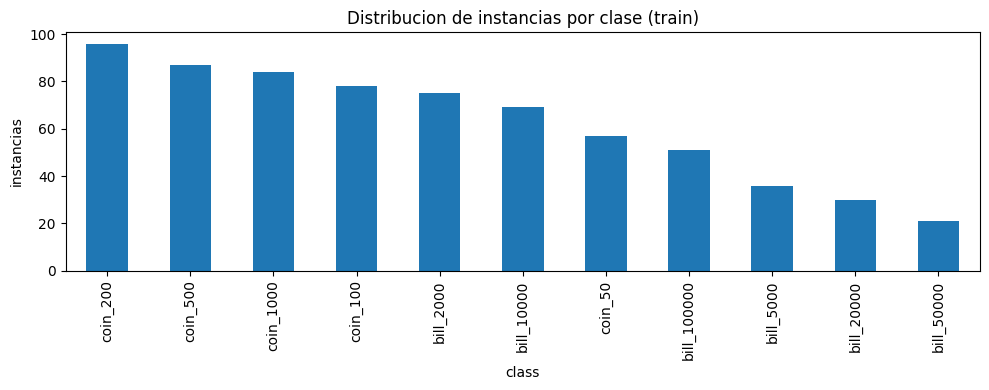

In [7]:
def count_instances(labels_dir):
    """Count ground-truth boxes per class id."""
    counts = Counter()
    if labels_dir is None or not Path(labels_dir).exists():
        return counts
    for txt in Path(labels_dir).rglob('*.txt'):
        for line in txt.read_text().splitlines():
            if line.strip():
                counts[int(line.split()[0])] += 1
    return counts

train_counts = count_instances(TRAIN_LABELS)

if not train_counts:
    print("WARNING: No se encontraron etiquetas en la carpeta de entrenamiento.")
    df_counts = pd.DataFrame(columns=['class', 'instances'])
else:
    df_counts = pd.DataFrame({
        'class': [CLASS_NAMES[i] for i in sorted(train_counts)],
        'instances': [train_counts[i] for i in sorted(train_counts)],
    }).sort_values('instances', ascending=False).reset_index(drop=True)

display(df_counts)

if not df_counts.empty:
    df_counts.plot.bar(x='class', y='instances', legend=False, figsize=(10, 4),
                       title='Distribucion de instancias por clase (train)')
    plt.ylabel('instancias')
    plt.tight_layout()
    plt.show()
else:
    print("No hay datos para graficar. Revisa que el dataset se haya descargado con etiquetas.")


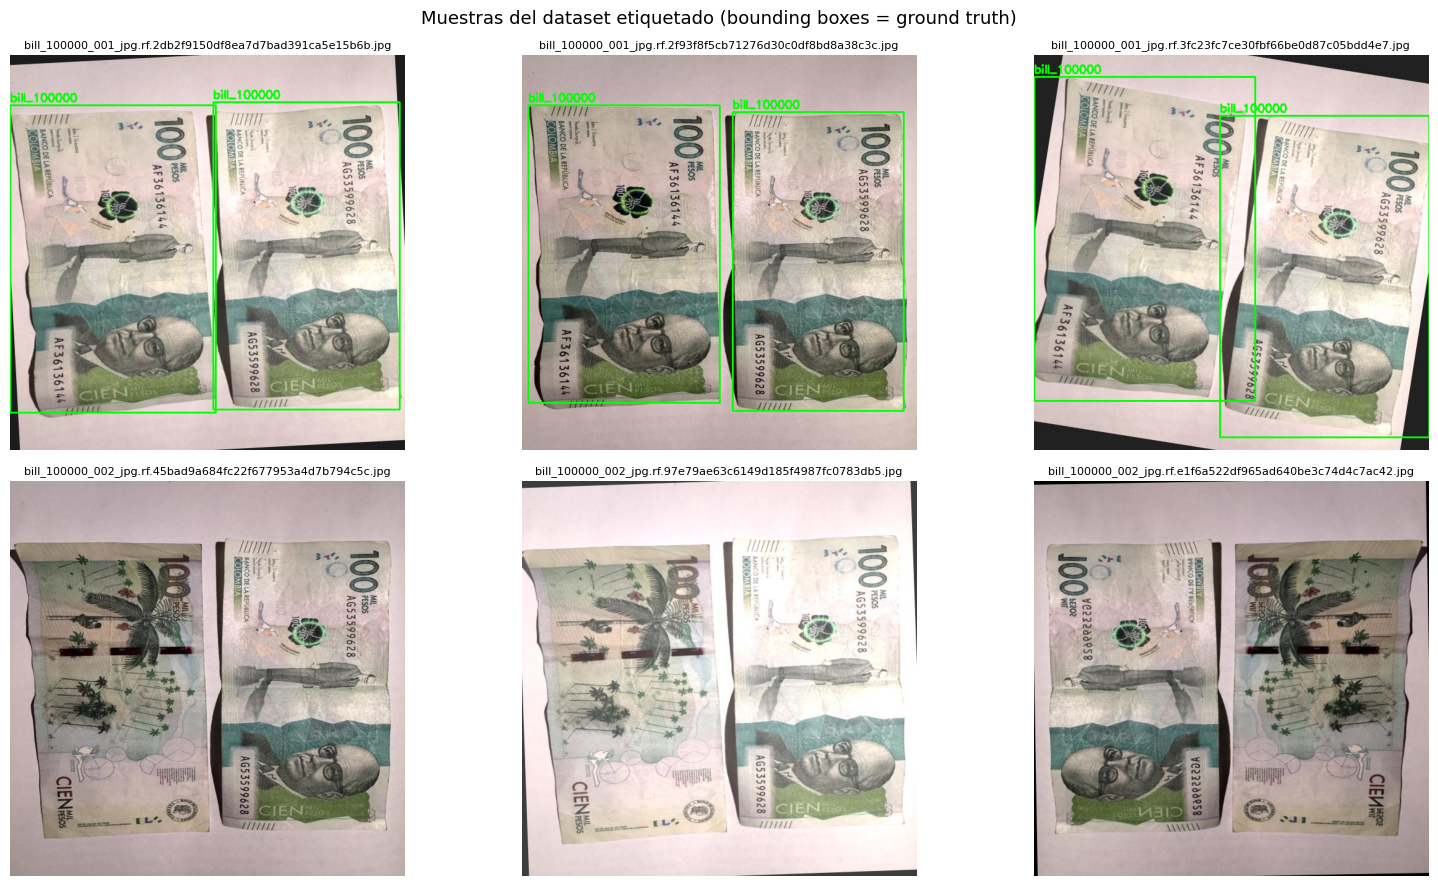

In [8]:
def draw_yolo_annotations(image_path, label_path, class_names, color=(0, 255, 0)):
    """Draw YOLO-format ground-truth boxes on an image (returns RGB array)."""
    img = cv2.imread(str(image_path))
    if img is None:
        return None
    h, w = img.shape[:2]
    label_path = Path(label_path)
    if label_path.exists():
        for line in label_path.read_text().splitlines():
            if not line.strip():
                continue
            try:
                cls_id, cx, cy, bw, bh = line.split()
                cls_id = int(cls_id)
                cx, cy, bw, bh = float(cx) * w, float(cy) * h, float(bw) * w, float(bh) * h
                x1, y1 = int(cx - bw / 2), int(cy - bh / 2)
                x2, y2 = int(cx + bw / 2), int(cy + bh / 2)
                cv2.rectangle(img, (x1, y1), (x2, y2), color, 2)
                cv2.putText(img, class_names[cls_id], (x1, max(20, y1 - 6)),
                            cv2.FONT_HERSHEY_SIMPLEX, 0.6, color, 2)
            except (ValueError, IndexError):
                continue
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

if TRAIN_IMAGES and TRAIN_IMAGES.exists():
    samples = sorted(TRAIN_IMAGES.glob('*.*'))[:6]
    if not samples:
        print("WARNING: La carpeta de entrenamiento no contiene imagenes.")
    else:
        fig, axes = plt.subplots(2, 3, figsize=(16, 9))
        for ax, img_path in zip(axes.ravel(), samples):
            lbl_path = TRAIN_LABELS / f'{img_path.stem}.txt'
            rendered = draw_yolo_annotations(img_path, lbl_path, CLASS_NAMES)
            if rendered is not None:
                ax.imshow(rendered)
                ax.set_title(img_path.name, fontsize=8)
            ax.axis('off')
        for ax in axes.ravel()[len(samples):]:
            ax.axis('off')
        plt.suptitle('Muestras del dataset etiquetado (bounding boxes = ground truth)', fontsize=13)
        plt.tight_layout()
        plt.show()
else:
    print("ERROR: No se pueden visualizar muestras porque no se encontro la carpeta de imagenes.")


## 4. Entrenamiento con Transfer Learning

### 4.1 Estrategia

Partimos de **`yolo11n.pt`** (pesos COCO pre-entrenados). El *backbone* ya conoce bordes, texturas y formas circulares genericas; solo re-entrenamos las capas de deteccion para nuestras clases. Esto reduce drasticamente el numero de imagenes necesarias y el tiempo de convergencia frente a entrenar *from scratch*.

### 4.2 Justificacion de hiperparametros

| Hiperparametro | Valor | Justificacion |
|---|---|---|
| `model` | `yolo11n.pt` | Nano: converge rapido en T4 y suficiente para objetos circulares bien definidos. |
| `epochs` | 100 | Dataset pequeno; con `patience=25` se detiene solo si no mejora. |
| `imgsz` | 640 | Estandar YOLO; resuelve el numeral pequeno de las monedas. |
| `batch` | 16 | Ajustado a los ~15 GB de una T4 con nano a 640 px. |
| `optimizer` | `auto` | Ultralytics selecciona AdamW/SGD segun el dataset. |
| `lr0` / `lrf` | 0.01 / 0.01 | LR inicial moderado (transfer learning) con decaimiento coseno para afinar al final. |
| `cos_lr` | `True` | Suaviza la convergencia (curva de loss mas estable). |
| `patience` | 25 | Early stopping: evita sobreajuste cuando `val/box_loss` empieza a subir. |
| `mosaic` | 1.0 (default) | Aumenta la diversidad de agrupaciones/oclusiones de forma sintetica. |
| `pretrained` | `True` | Habilita transfer learning desde COCO. |
| `amp` | `True` | Mixed precision: menos VRAM y ~2x mas rapido en GPU. |

> **Lectura de las graficas:** el *overfitting* se detecta cuando `train/*_loss` sigue bajando mientras `val/*_loss` se estanca o sube. La metrica objetivo es **`mAP50-95(B)`**, el indicador oficial de Ultralytics.


In [9]:
# Transfer learning on the custom coin dataset
MODEL_BASE = 'yolo11n.pt'
RUN_NAME = 'yolo11n_coins'

model = YOLO(MODEL_BASE)

results = model.train(
    data=str(DATA_YAML),
    epochs=100,
    imgsz=640,
    batch=16,
    patience=25,
    optimizer='auto',
    lr0=0.01,
    lrf=0.01,
    momentum=0.937,
    weight_decay=0.0005,
    warmup_epochs=3.0,
    cos_lr=True,
    cache=True,
    pretrained=True,
    amp=True,
    seed=SEED,
    deterministic=True,
    project='runs/coins',
    name=RUN_NAME,
    exist_ok=True,
    plots=True,
    val=True,
)

RUN_DIR = Path(model.trainer.save_dir).resolve()
BEST_WEIGHTS = RUN_DIR / 'weights' / 'best.pt'
print('Run dir     :', RUN_DIR)
print('Best weights:', BEST_WEIGHTS)


Ultralytics 8.4.182 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=True, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/content/Deteccion_Divisas-1/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolo11n_coins, nbs=64, nms=None, opset=None, optimize

,epoch,time,train/box_loss,train/cls_loss,train/dfl_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),val/box_loss,val/cls_loss,val/dfl_loss,lr/pg0,lr/pg1,lr/pg2
97,98,561.832,0.15117,0.16920,0.83604,0.99714,0.98250,0.98354,0.97930,0.14200,0.15481,0.78145,0.000008,0.000008,0.000008
98,99,567.237,0.14427,0.16352,0.81782,0.99718,0.98254,0.98350,0.97889,0.14295,0.15412,0.78082,0.000007,0.000007,0.000007
99,100,572.673,0.14238,0.15632,0.82872,0.99725,0.98254,0.98335,0.97838,0.14226,0.15393,0.78017,0.000007,0.000007,0.000007


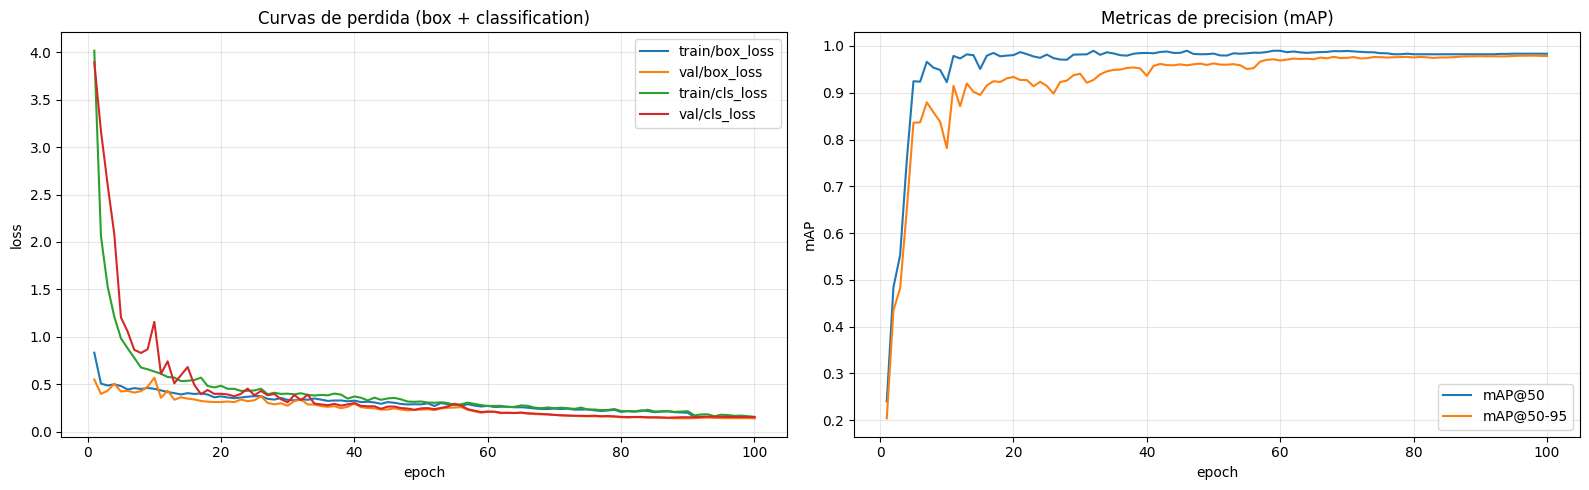

In [10]:
# Training history: loss and mAP curves
df_hist = pd.read_csv(RUN_DIR / 'results.csv')
df_hist.columns = [c.strip() for c in df_hist.columns]
display(df_hist.tail(3))

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

axes[0].plot(df_hist['epoch'], df_hist['train/box_loss'], label='train/box_loss')
axes[0].plot(df_hist['epoch'], df_hist['val/box_loss'], label='val/box_loss')
axes[0].plot(df_hist['epoch'], df_hist['train/cls_loss'], label='train/cls_loss')
axes[0].plot(df_hist['epoch'], df_hist['val/cls_loss'], label='val/cls_loss')
axes[0].set_title('Curvas de perdida (box + classification)')
axes[0].set_xlabel('epoch')
axes[0].set_ylabel('loss')
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(df_hist['epoch'], df_hist['metrics/mAP50(B)'], label='mAP@50')
axes[1].plot(df_hist['epoch'], df_hist['metrics/mAP50-95(B)'], label='mAP@50-95')
axes[1].set_title('Metricas de precision (mAP)')
axes[1].set_xlabel('epoch')
axes[1].set_ylabel('mAP')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


## 5. Validacion y metricas

Evaluamos los mejores pesos (`best.pt`) sobre el split de validacion, que el modelo **no** usa para actualizar gradientes.


In [11]:
best_model = YOLO(str(BEST_WEIGHTS))

metrics = best_model.val(
    data=str(DATA_YAML),
    split='val',
    imgsz=640,
    batch=16,
    plots=True,
    project='runs/coins',
    name=f'{RUN_NAME}_val',
    exist_ok=True,
)

print(f'mAP@50    : {metrics.box.map50:.4f}')
print(f'mAP@50-95 : {metrics.box.map:.4f}')
print(f'Precision : {metrics.box.mp:.4f}')
print(f'Recall    : {metrics.box.mr:.4f}')

per_class = pd.DataFrame({
    'class': [CLASS_NAMES[int(c)] for c in metrics.box.ap_class_index],
    'precision': metrics.box.p,
    'recall': metrics.box.r,
    'mAP@50': metrics.box.ap50,
    'mAP@50-95': metrics.box.ap,
}).sort_values('mAP@50-95', ascending=False).reset_index(drop=True)

display(per_class)


Ultralytics 8.4.182 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,599,481 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1784.7±516.3 MB/s, size: 63.0 KB)
val: Scanning /content/Deteccion_Divisas-1/train/labels.cache... 288 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 288/288 86.3Mit/s 0.0s
WARNING ⚠️ Box and segment counts should be equal, but got len(segments) = 672, len(boxes) = 684. To resolve this only boxes will be used and all segments will be removed. To avoid this please supply either a detect or segment dataset, not a detect-segment mixed dataset.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 18/18 3.7it/s 4.8s
                   all        288        684      0.997      0.982      0.984      0.979
            bill_10000         66         69      0.997      0.957      0.969      0.958
           bill_100000      

,class,precision,recall,mAP@50,mAP@50-95
0,coin_200,0.997683,1.000000,0.995000,0.995000
1,bill_50000,0.991486,1.000000,0.995000,0.995000
2,coin_100,0.997380,1.000000,0.995000,0.995000
3,coin_1000,0.997424,1.000000,0.995000,0.995000
4,coin_50,0.997162,1.000000,0.995000,0.992860
5,bill_5000,1.000000,0.993010,0.995000,0.992750
6,bill_100000,0.997014,1.000000,0.995000,0.990041
7,bill_2000,1.000000,0.989932,0.995000,0.989451
8,coin_500,1.000000,0.967889,0.994667,0.977320
9,bill_10000,0.997064,0.956522,0.969253,0.957586


confusion_matrix_normalized.png


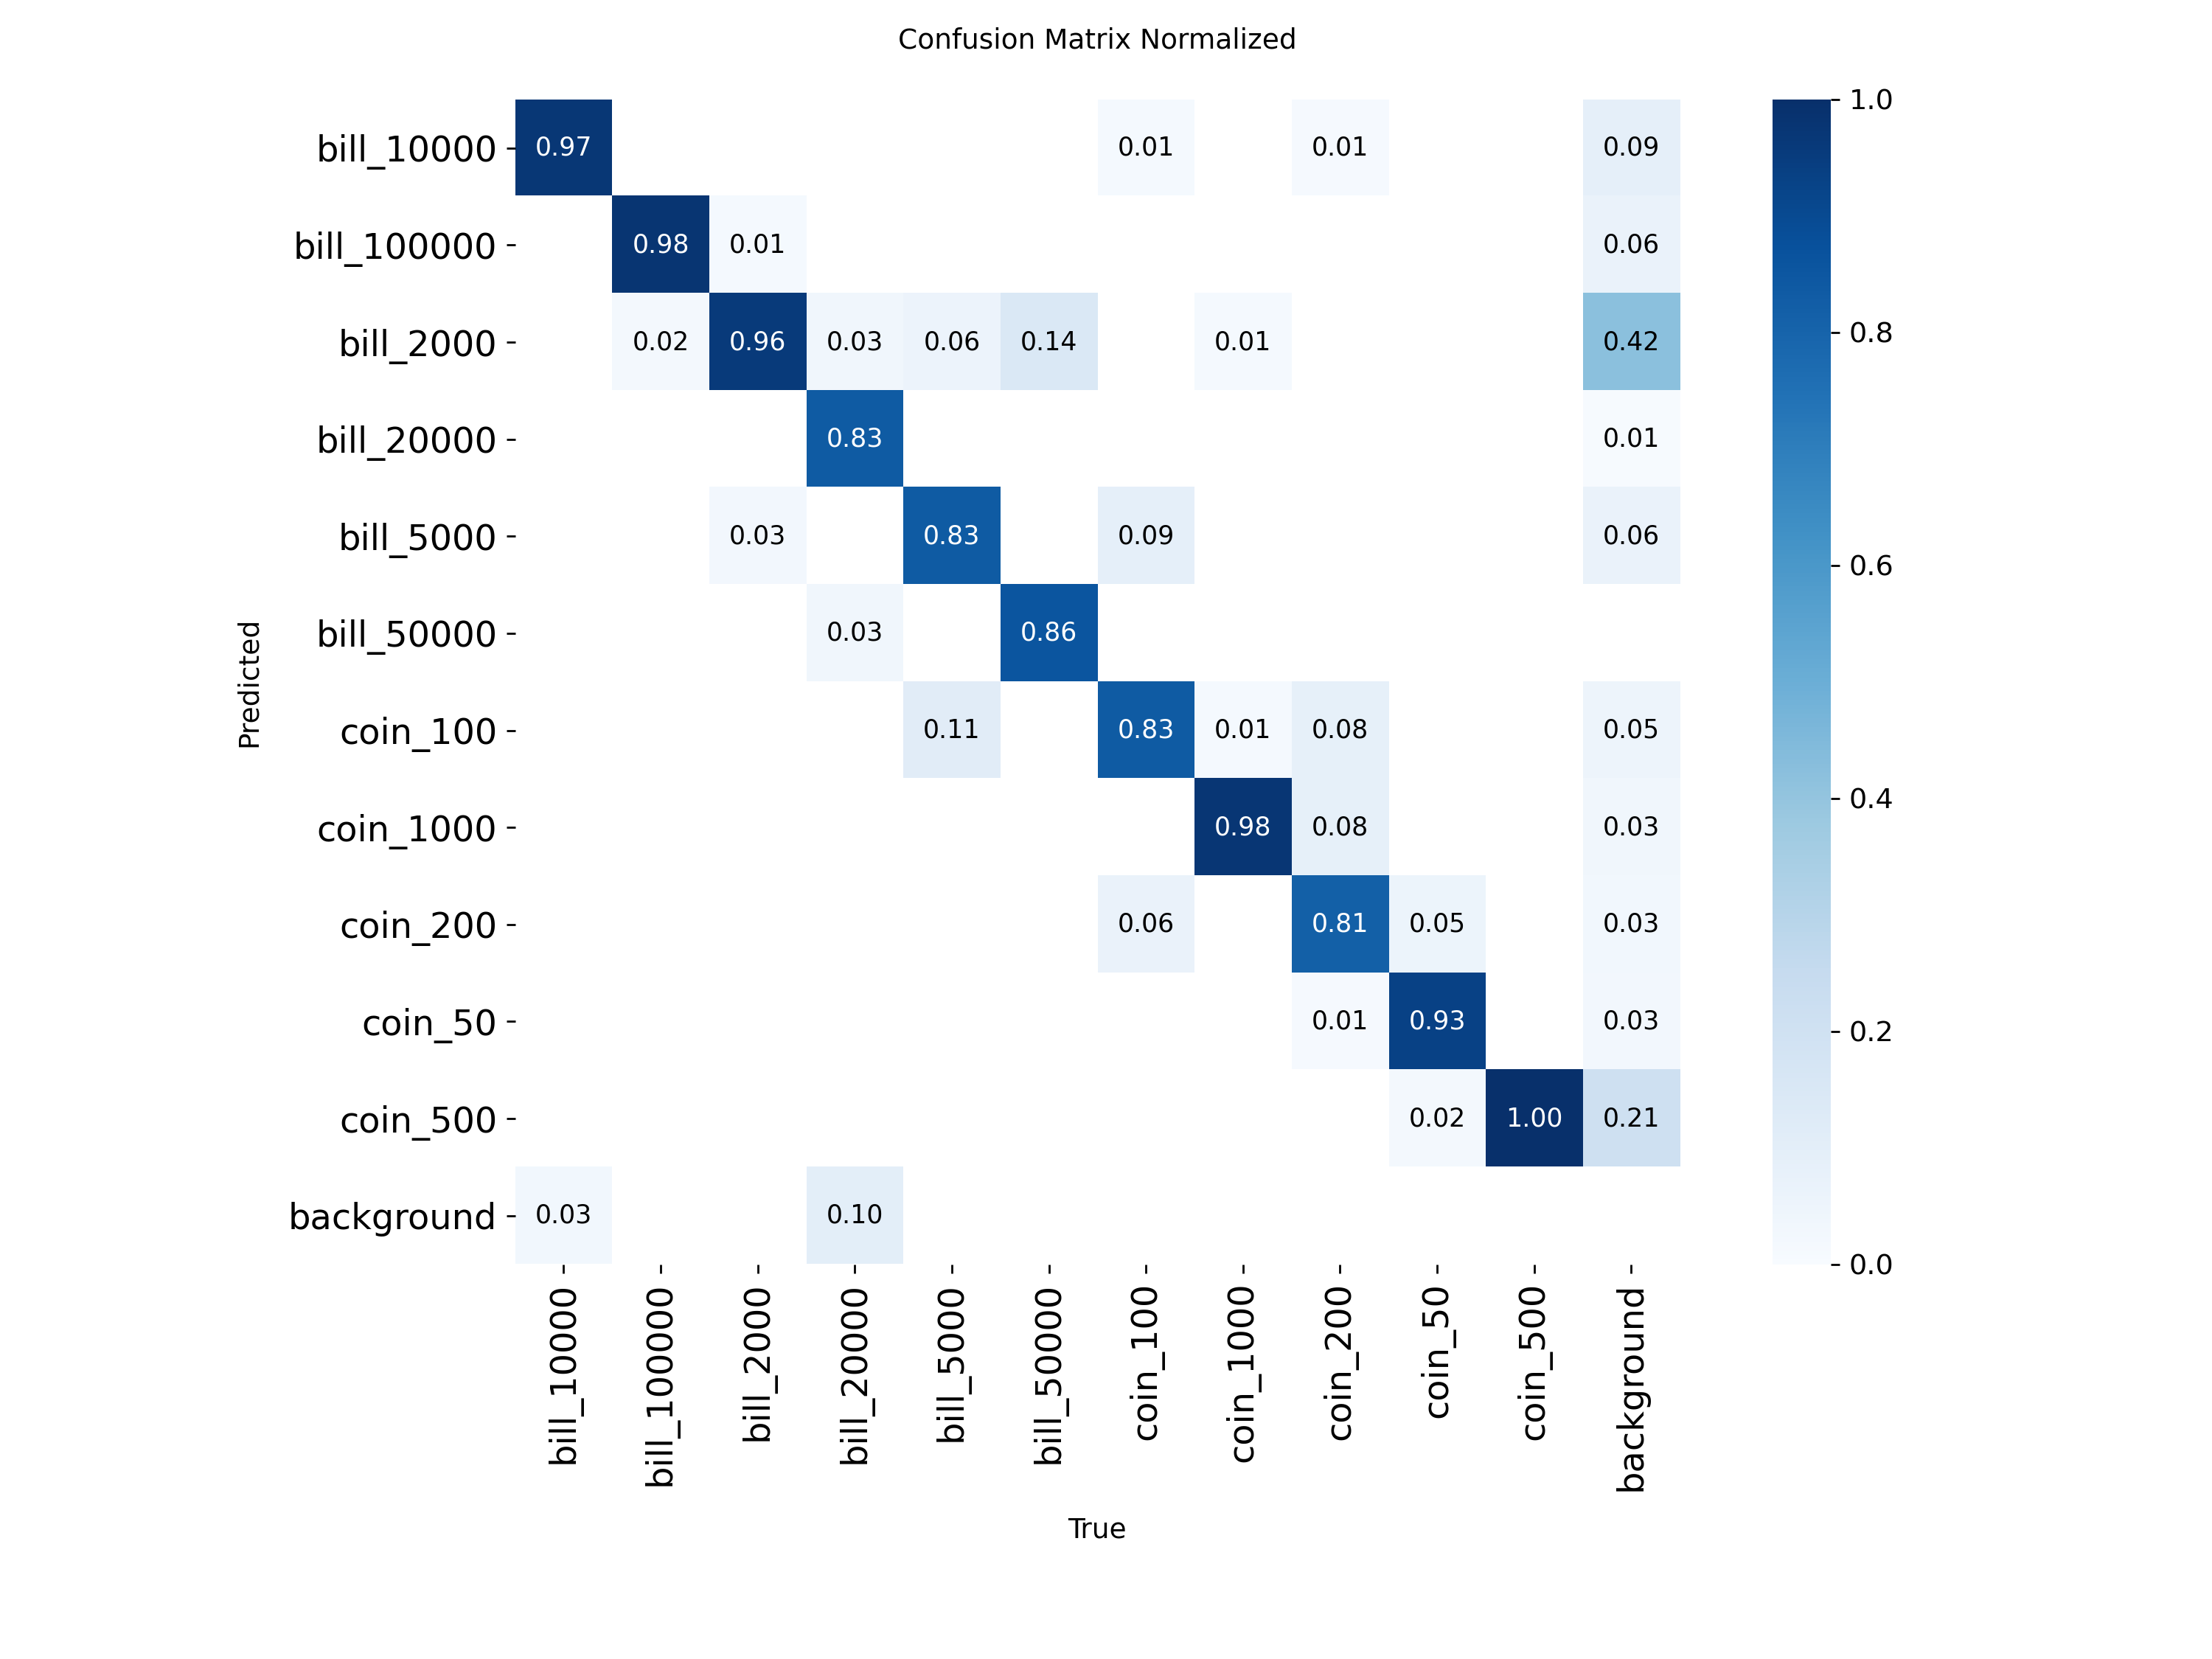

confusion_matrix.png


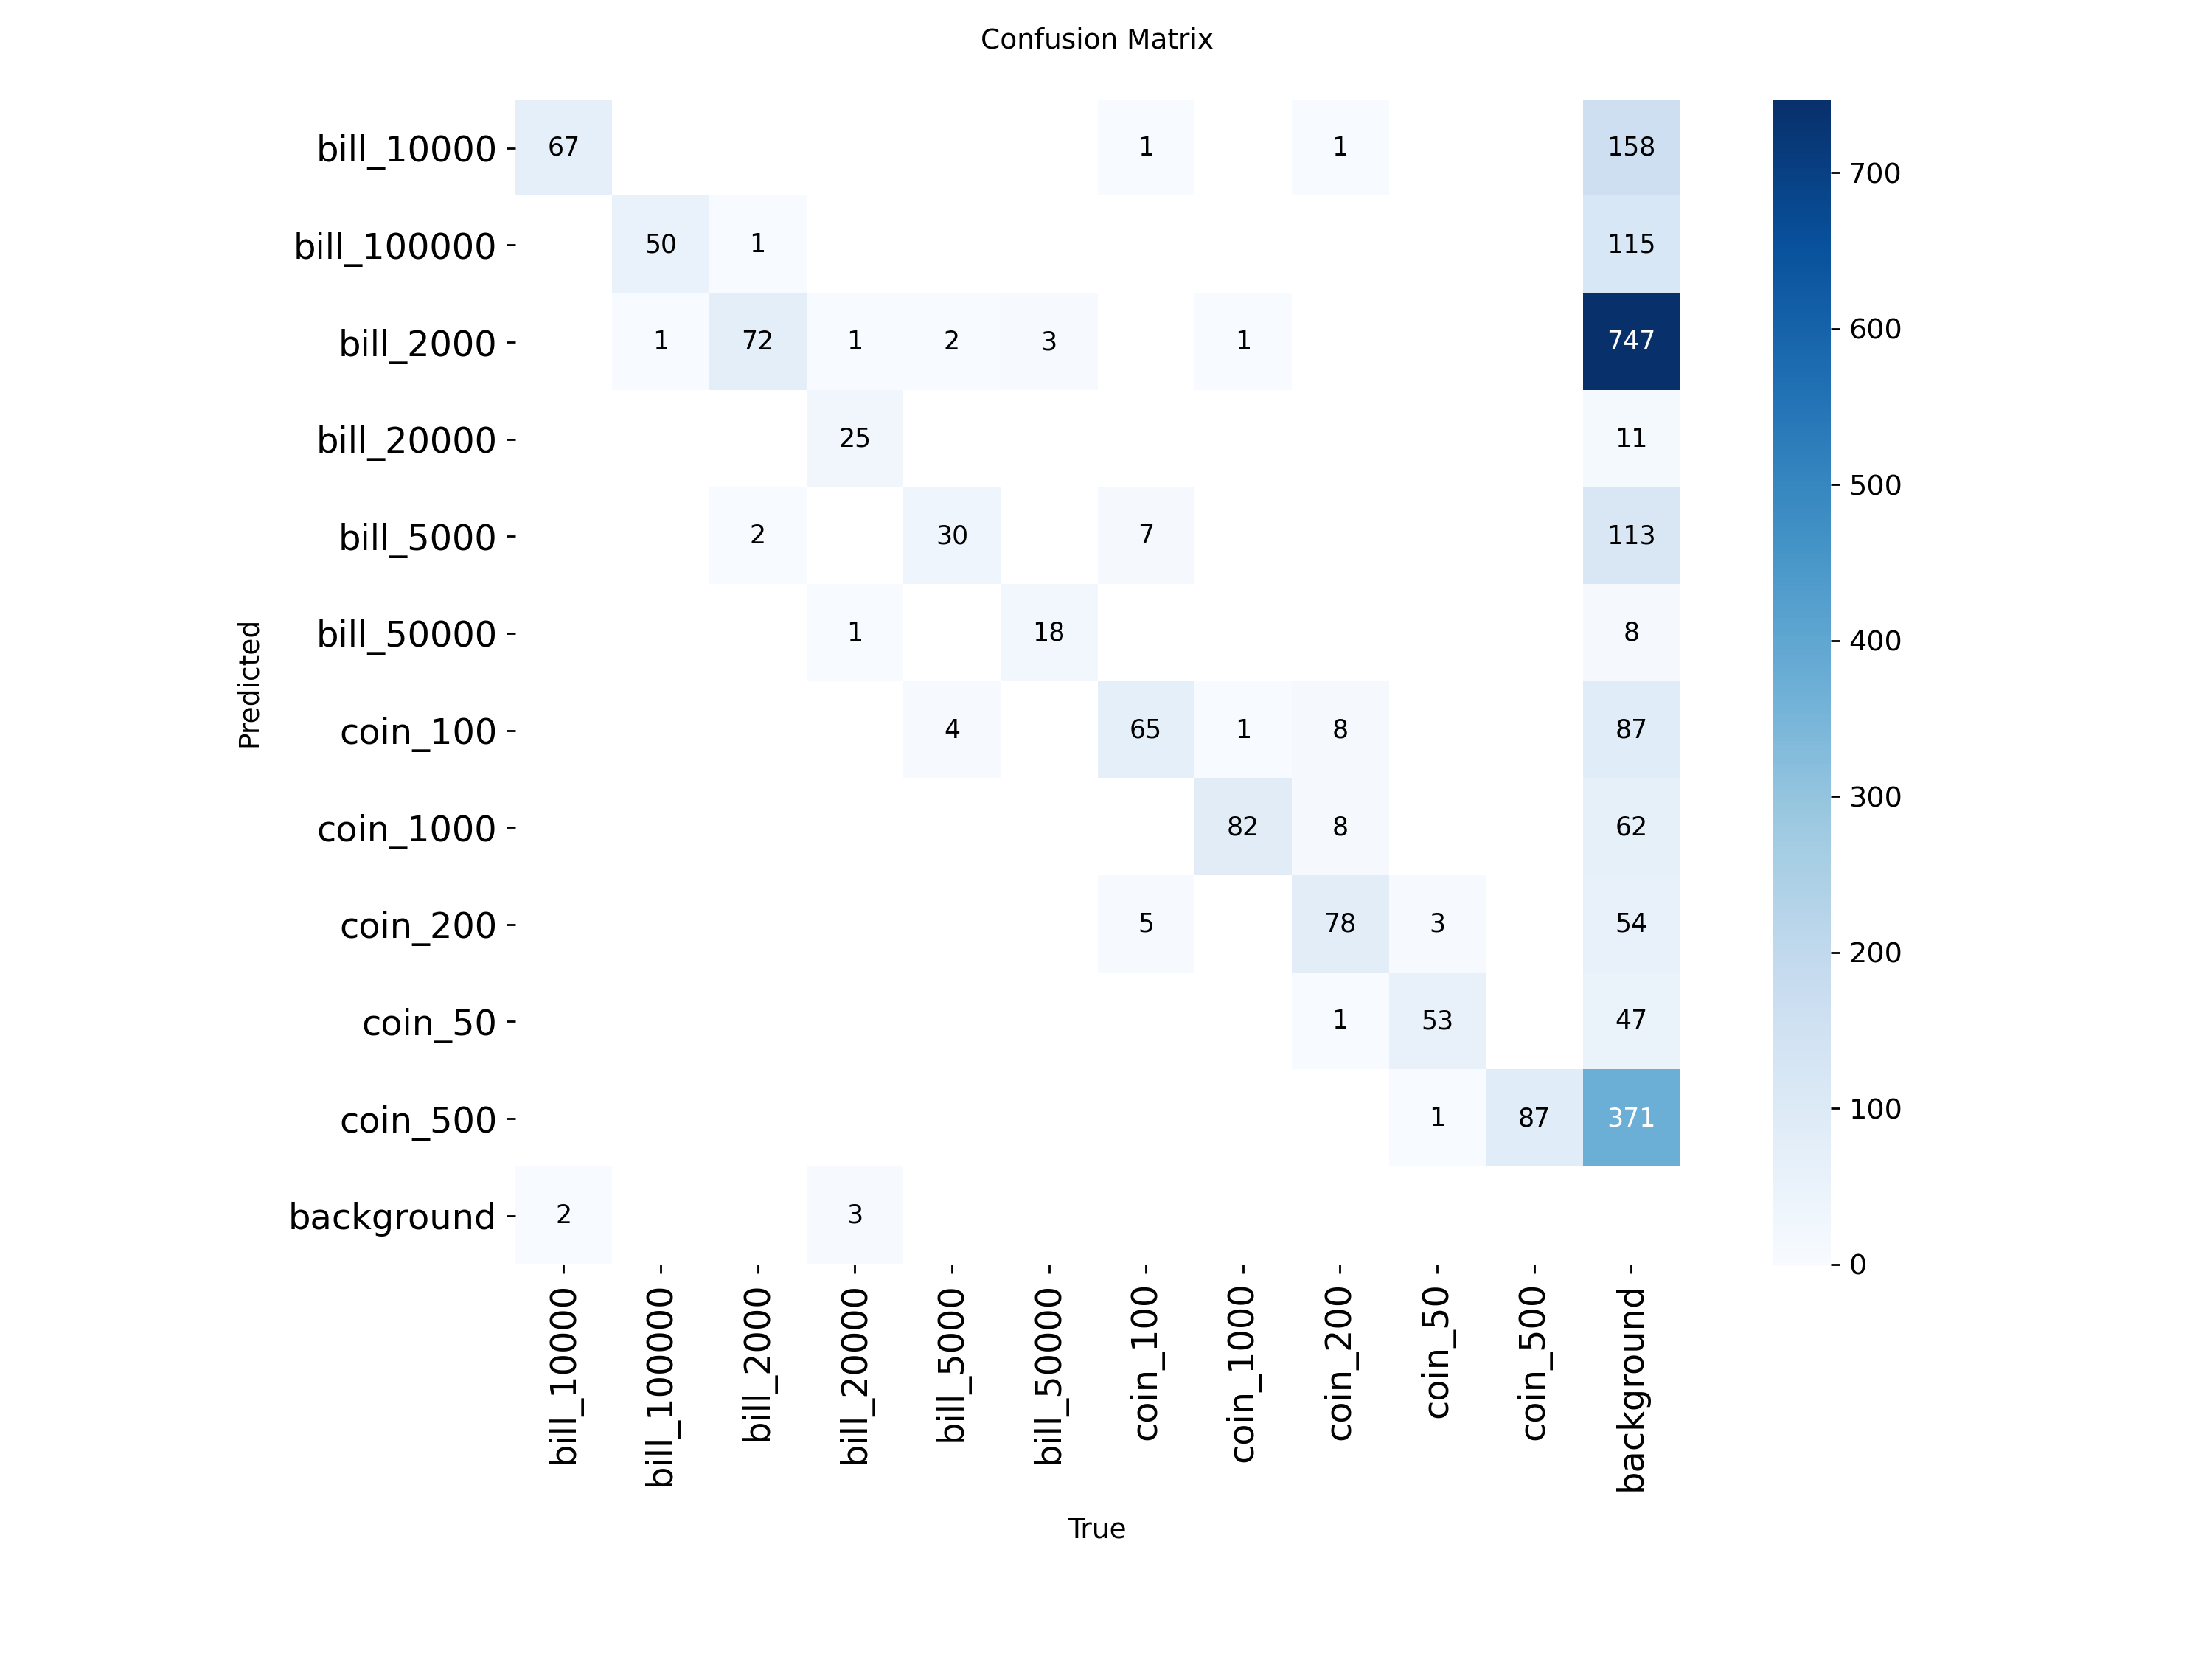

val_batch0_labels.jpg


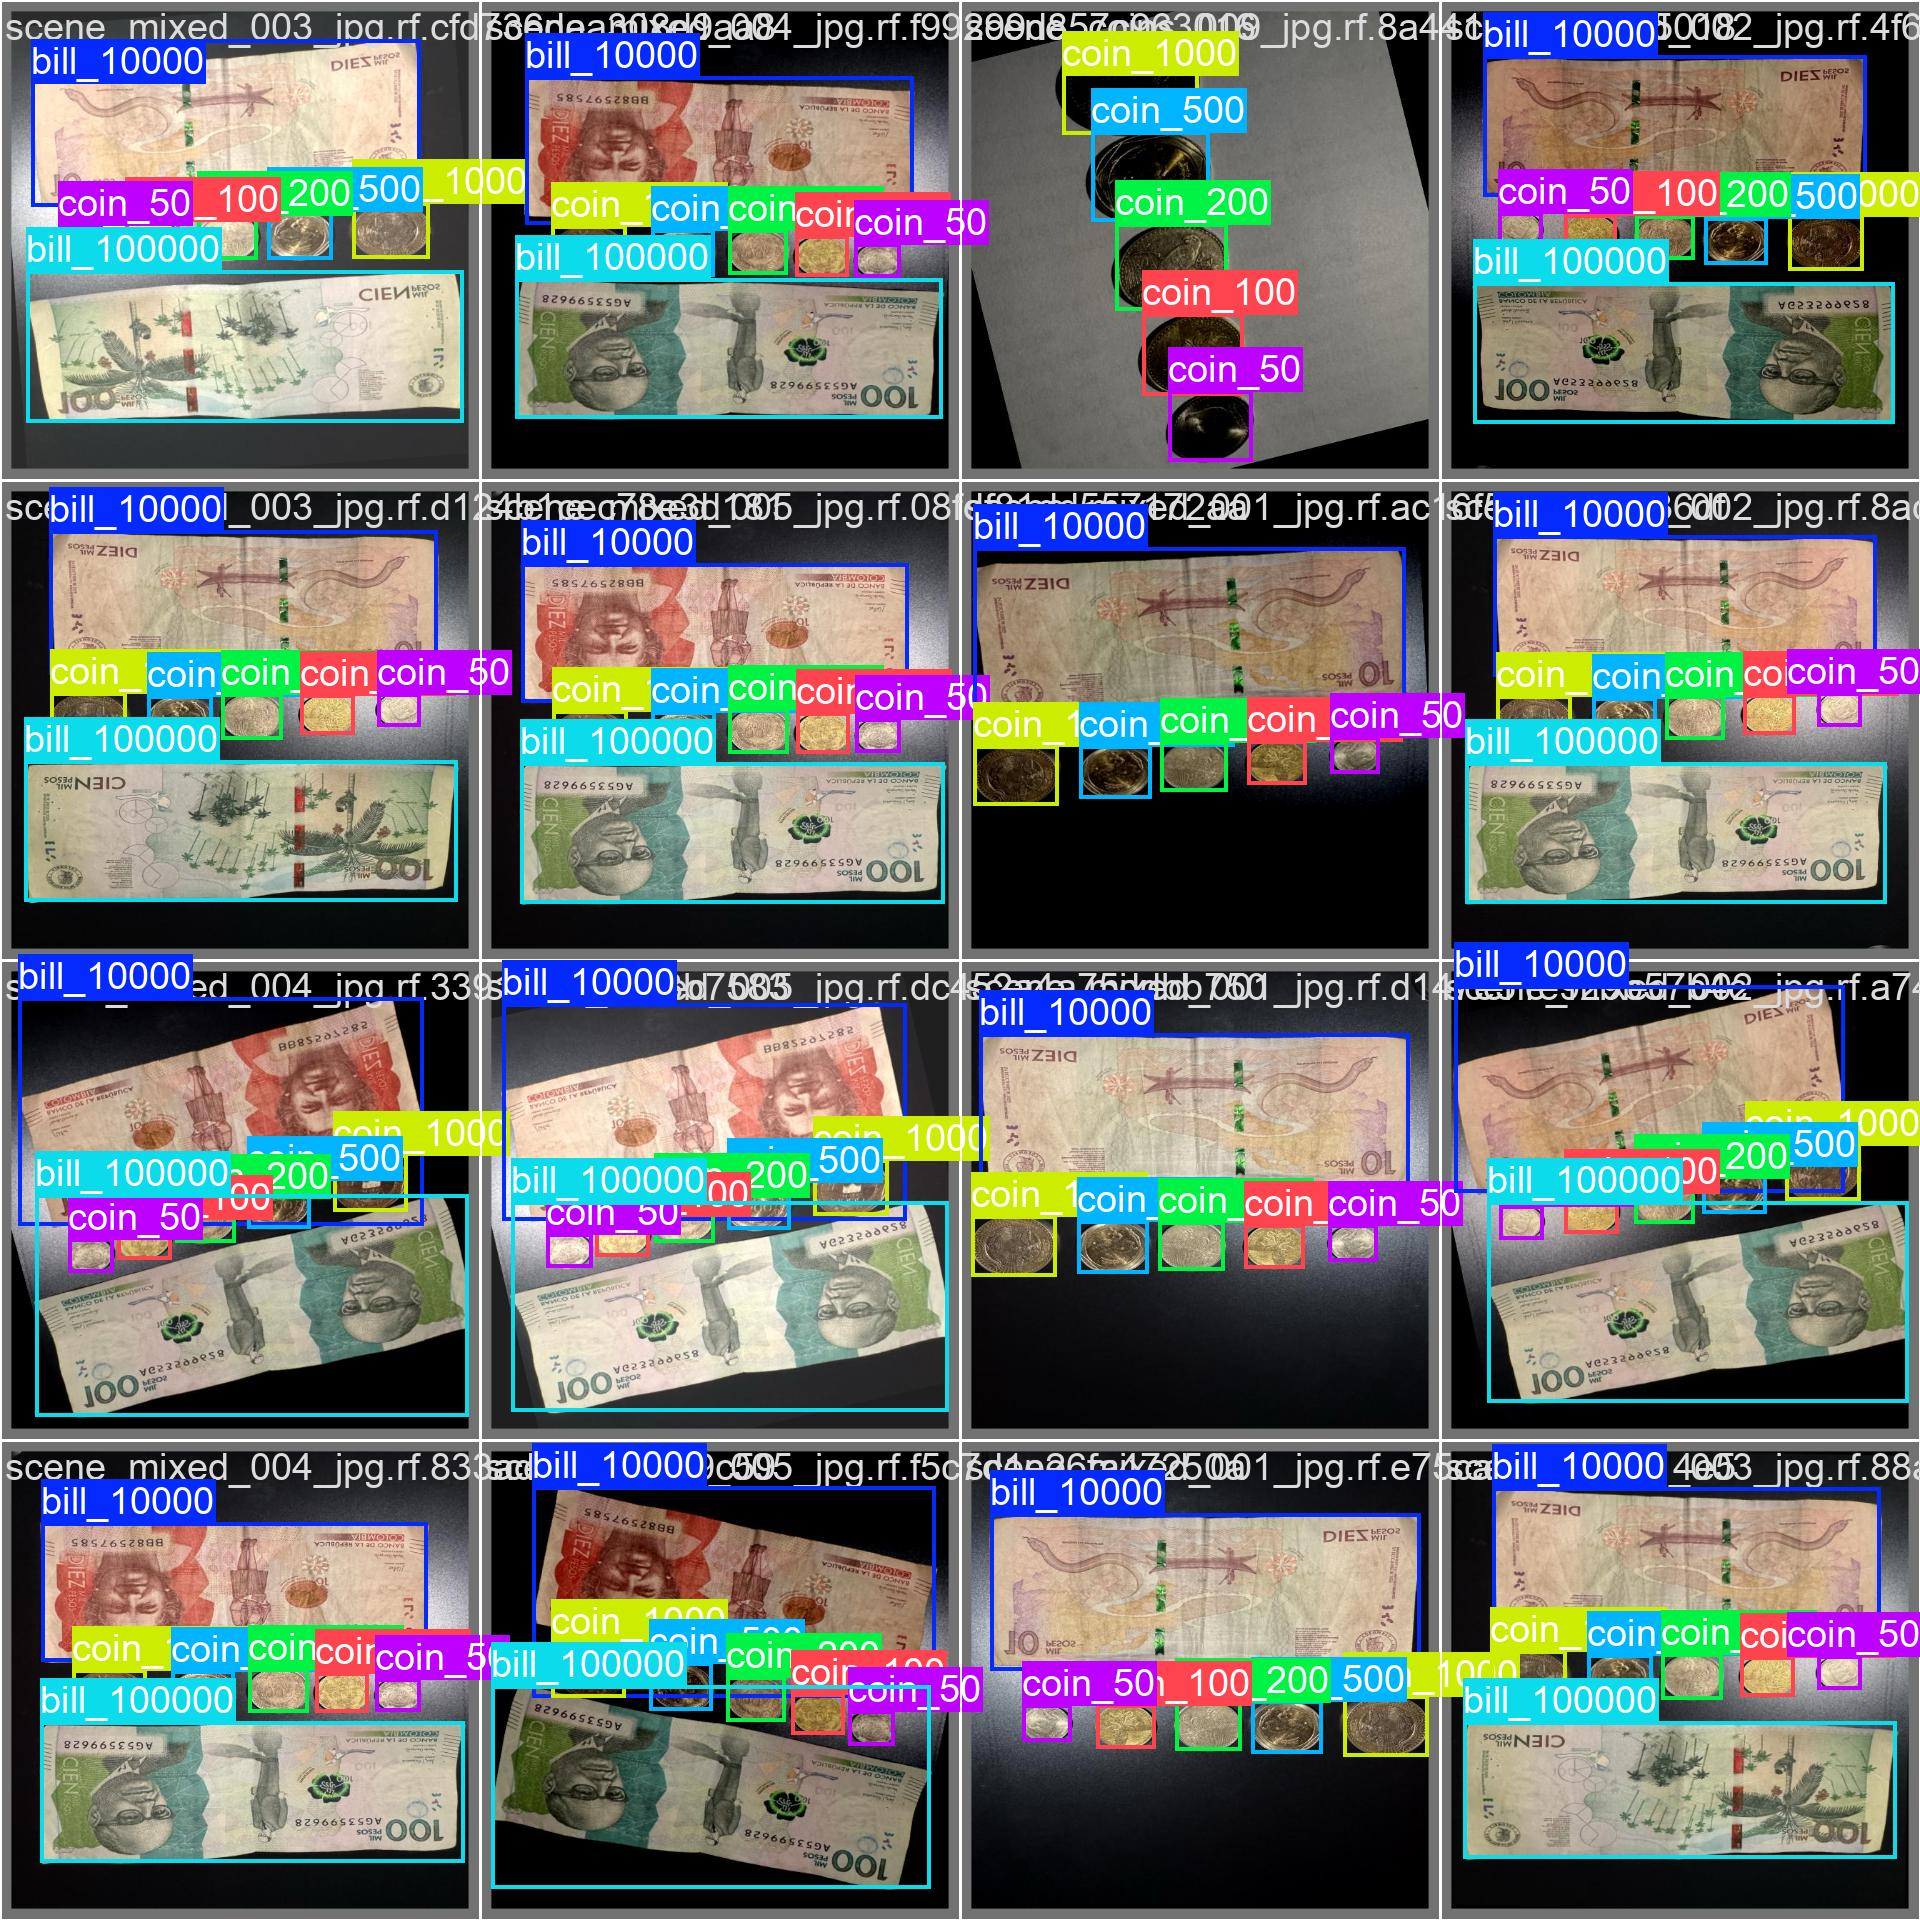

val_batch0_pred.jpg


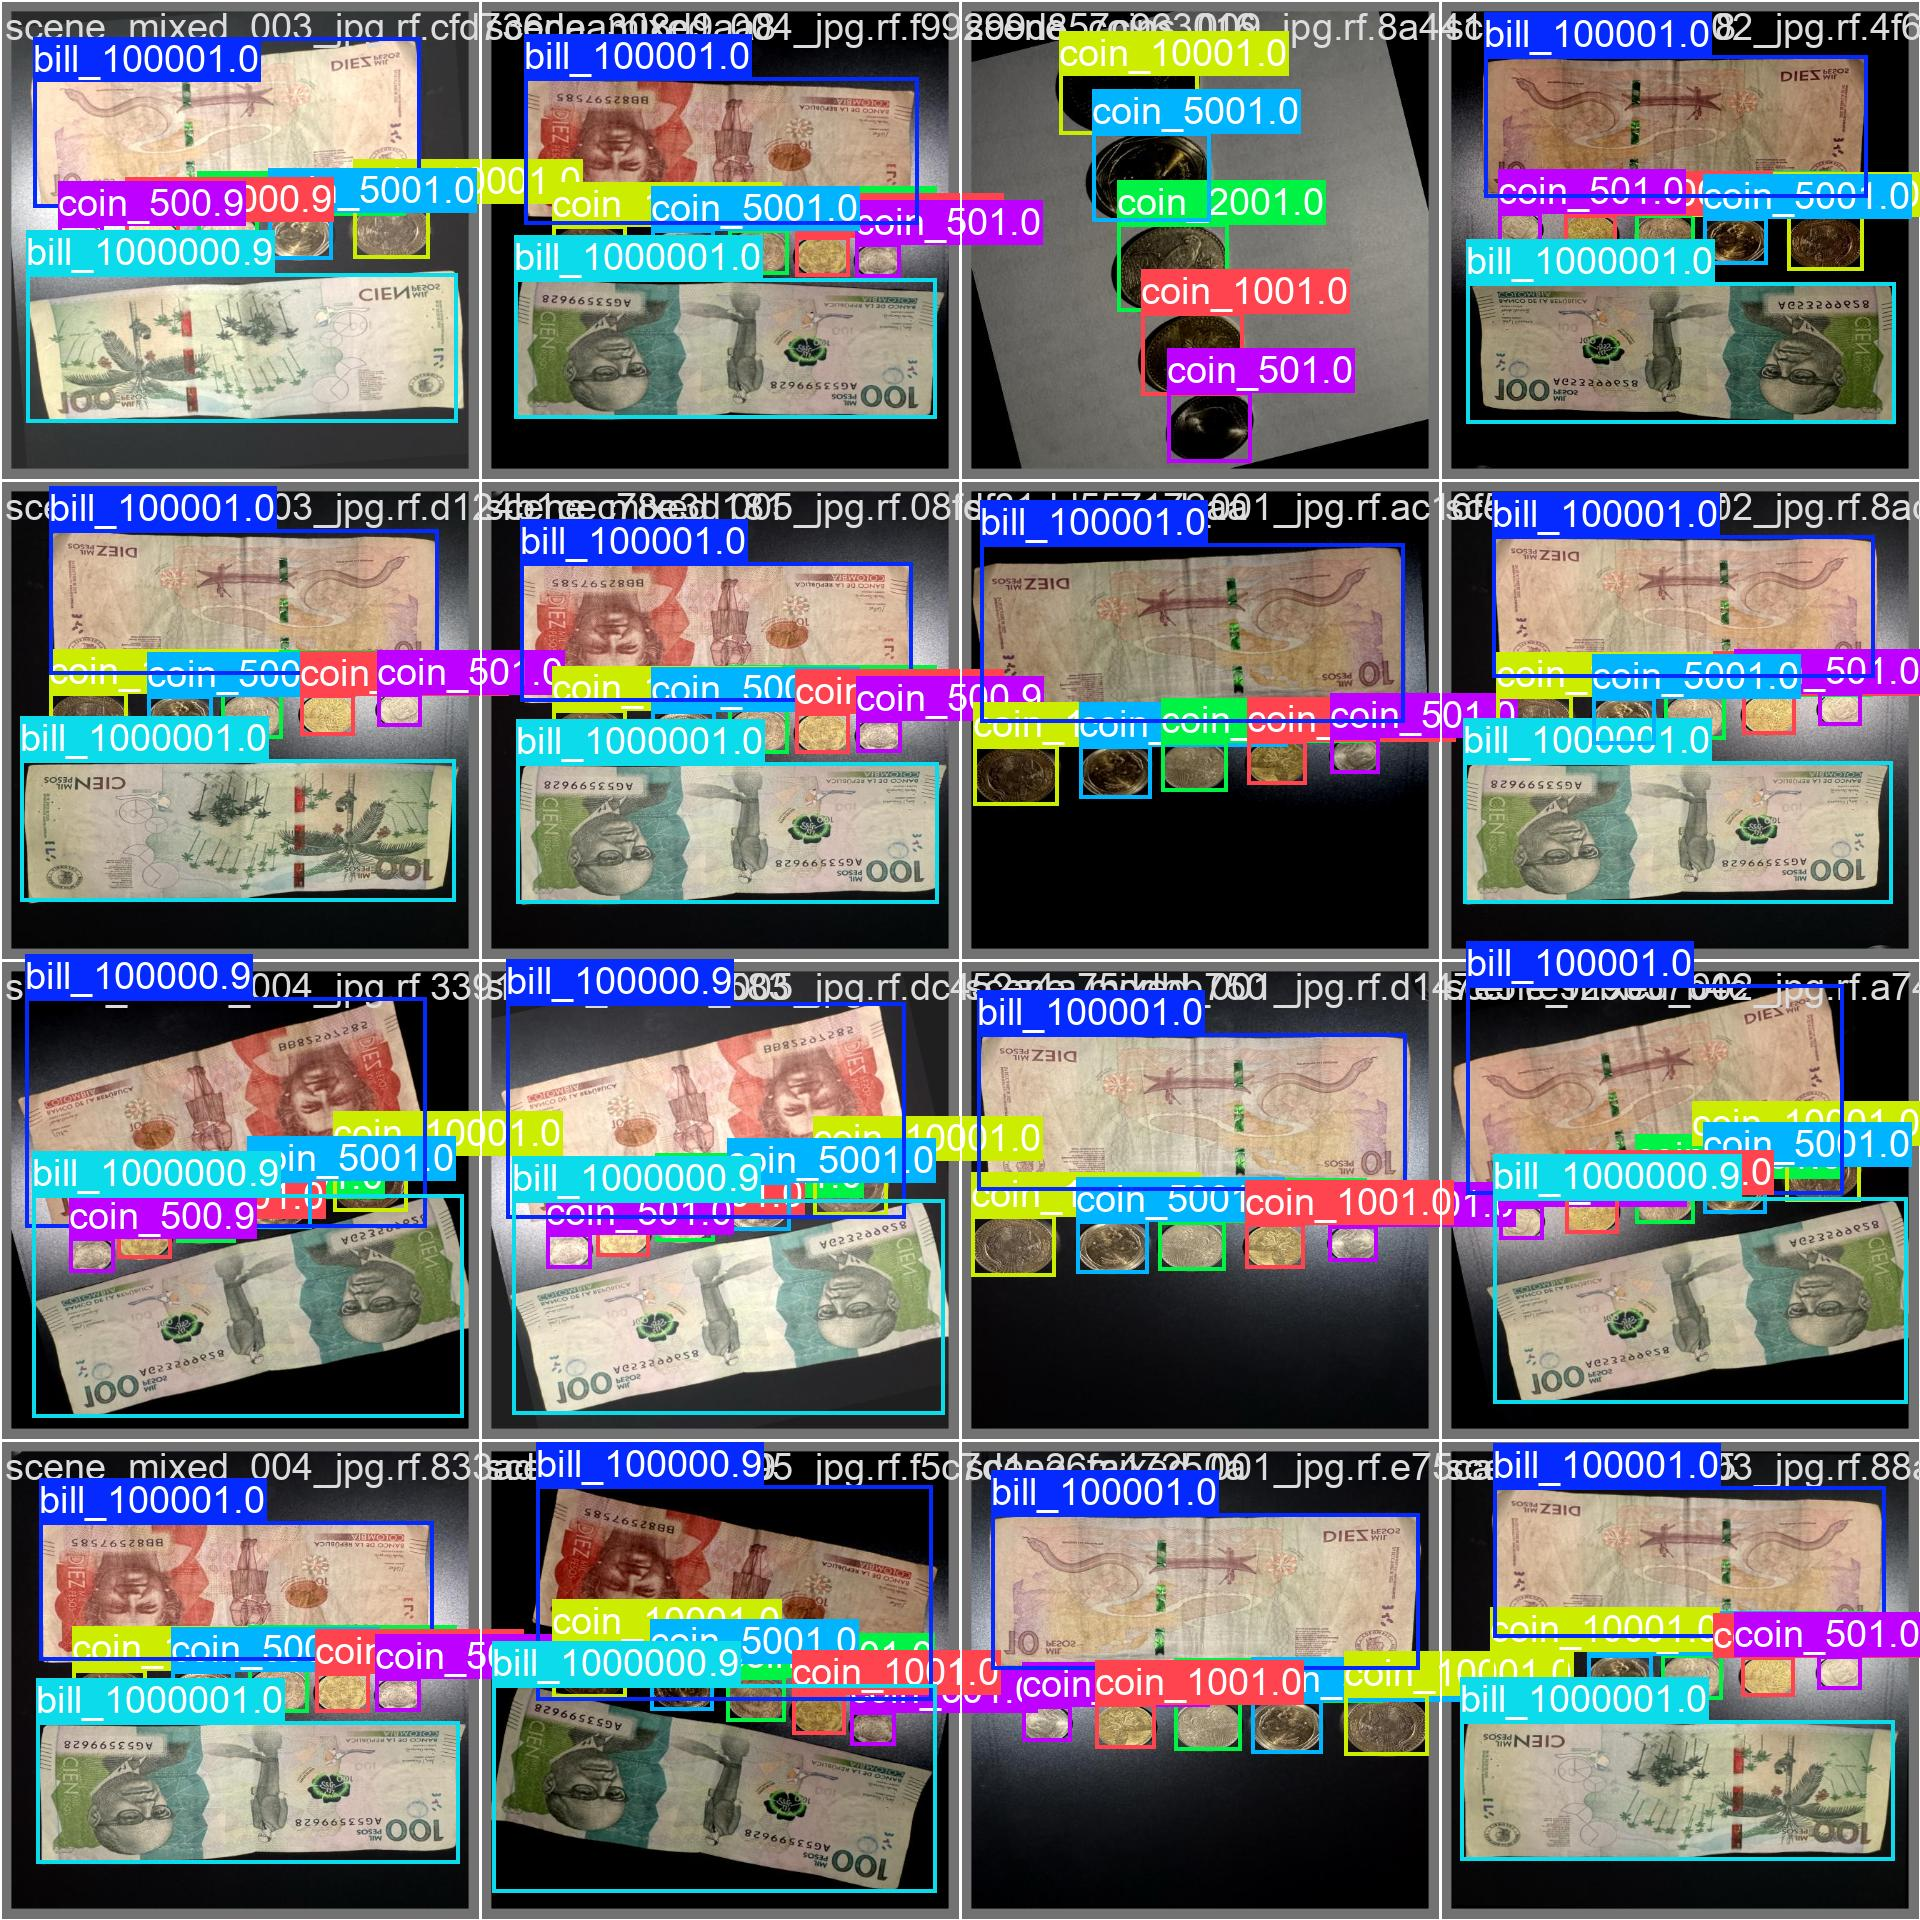

In [12]:
# Confusion matrix + Ultralytics summary plots
from IPython.display import Image as IPImage

VAL_DIR = Path(metrics.save_dir).resolve()
for fname in ('confusion_matrix_normalized.png', 'confusion_matrix.png'):
    fpath = VAL_DIR / fname
    if fpath.exists():
        print(fname)
        display(IPImage(filename=str(fpath), width=760))

# Example failures: predictions vs ground truth side by side
val_preds = VAL_DIR / 'val_batch0_pred.jpg'
val_labels = VAL_DIR / 'val_batch0_labels.jpg'
for fpath in (val_labels, val_preds):
    if fpath.exists():
        print(fpath.name)
        display(IPImage(filename=str(fpath), width=900))


## 6. Inferencia + logica de cuantificacion monetaria

**Nucleo logico del reto.** Tras el *forward pass*, extraemos del tensor de salida la clase y la confianza de cada deteccion y mapeamos cada clase a un **valor matematico** (pesos colombianos) para calcular la sumatoria total de dinero en la escena.

- `result.boxes.cls` -> indice de clase predicha
- `result.boxes.conf` -> confianza de cada caja
- `result.names` -> diccionario `{id: 'coin_100'}`
- `CLASS_VALUES` -> tabla de equivalencia clase -> valor nominal


In [13]:
# Class -> nominal value mapping (Colombian pesos)
CLASS_VALUES = {
    'coin_50': 50,
    'coin_100': 100,
    'coin_200': 200,
    'coin_500': 500,
    'coin_1000': 1000,
    'bill_2000': 2000,
    'bill_5000': 5000,
    'bill_10000': 10000,
    'bill_20000': 20000,
    'bill_50000': 50000,
    'bill_100000': 100000,
}

CURRENCY = '$'
CONF_THRESHOLD = 0.35
IOU_THRESHOLD = 0.50


def cop(amount):
    """Format an integer amount as Colombian pesos (dot as thousands separator)."""
    return f'{CURRENCY}{amount:,}'.replace(',', '.')


def build_summary(counter):
    """Build a human-readable sentence from a {label: count} mapping."""
    if not counter:
        return 'No se detectaron objetos en la escena.'
    parts = []
    for label, n in sorted(counter.items(), key=lambda kv: CLASS_VALUES.get(kv[0], 0)):
        noun = 'moneda' if n == 1 else 'monedas'
        value = CLASS_VALUES.get(label)
        if value is None:
            parts.append(f"{n} {noun} de clase '{label}' (valor no registrado)")
        else:
            parts.append(f'{n} {noun} de {cop(value)}')
    total = sum(CLASS_VALUES.get(lbl, 0) * n for lbl, n in counter.items())
    return f"Se detectaron {', '.join(parts)}. Total en escena: {cop(total)}"


def quantify_money(image_path, model, conf=CONF_THRESHOLD, iou=IOU_THRESHOLD, imgsz=640):
    """Run inference on an image and return detections, per-class counts and total value."""
    result = model.predict(
        source=str(image_path), conf=conf, iou=iou, imgsz=imgsz, verbose=False,
    )[0]

    names = result.names
    labels = [names[int(c)] for c in result.boxes.cls] if result.boxes is not None else []
    counter = Counter(labels)
    total = sum(CLASS_VALUES.get(lbl, 0) * n for lbl, n in counter.items())

    return {
        'image': str(image_path),
        'result': result,
        'counter': dict(counter),
        'total': total,
        'summary': build_summary(counter),
    }


def show_prediction(image_path, model, conf=CONF_THRESHOLD, iou=IOU_THRESHOLD, imgsz=640):
    """Visualize the prediction with boxes overlaid and print the money summary."""
    info = quantify_money(image_path, model, conf=conf, iou=iou, imgsz=imgsz)

    fig, axes = plt.subplots(1, 2, figsize=(16, 7))
    axes[0].imshow(PILImage.open(image_path))
    axes[0].set_title('Imagen de entrada', fontsize=11)
    axes[0].axis('off')

    annotated = info['result'].plot()
    axes[1].imshow(cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB))
    axes[1].set_title(info['summary'], fontsize=11)
    axes[1].axis('off')

    plt.tight_layout()
    plt.show()

    print(info['summary'])
    for label, n in info['counter'].items():
        print(f"  - {label}: {n} x {cop(CLASS_VALUES.get(label, 0))}")
    return info


### 6.1 Validacion final sobre una imagen no vista

Sube una foto nueva (no incluida en `train`/`val`) de una escena con varias monedas y ejecuta la celda. El resultado es el entregable final: cajas sobrepuestas + conteo + sumatoria total.


In [27]:
# Upload an unseen scene (runs only in Colab)
from google.colab import files

uploaded = files.upload()
TEST_IMAGE = Path(next(iter(uploaded)))
print('Imagen subida:', TEST_IMAGE)


Saving WhatsApp Image 2026-10-18 at 23.44.03.jpeg to WhatsApp Image 2026-10-18 at 23.44.03.jpeg
Imagen subida: WhatsApp Image 2026-10-18 at 23.44.03.jpeg


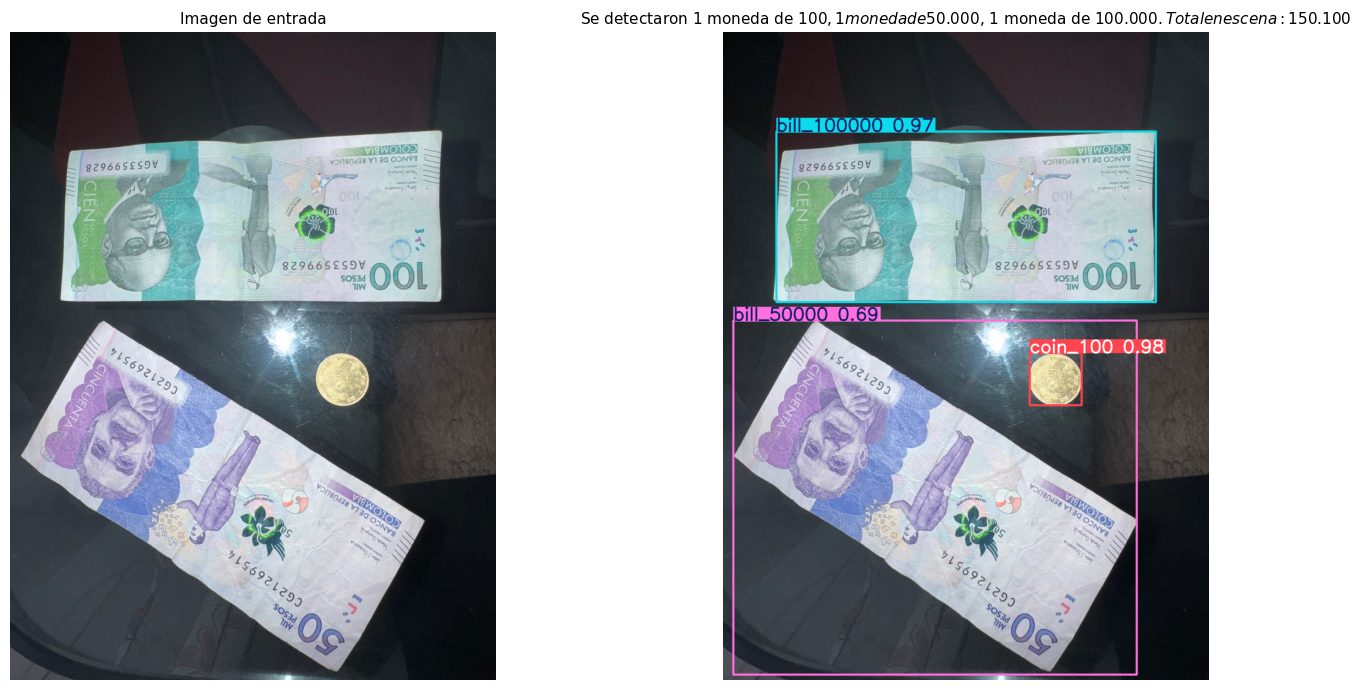

Se detectaron 1 moneda de $100, 1 moneda de $50.000, 1 moneda de $100.000. Total en escena: $150.100
  - coin_100: 1 x $100
  - bill_100000: 1 x $100.000
  - bill_50000: 1 x $50.000

Resumen del conteo por clase:


,clase,cantidad,valor_unitario,subtotal
0,coin_100,1,$100,$100
1,bill_100000,1,$100.000,$100.000
2,bill_50000,1,$50.000,$50.000


In [28]:
# Final validation: boxes + counting + total value
result_unseen = show_prediction(TEST_IMAGE, best_model)

print('\nResumen del conteo por clase:')
display(pd.DataFrame(
    [{'clase': k, 'cantidad': v, 'valor_unitario': cop(CLASS_VALUES.get(k, 0)),
      'subtotal': cop(CLASS_VALUES.get(k, 0) * v)} for k, v in result_unseen['counter'].items()]
))


### 6.2 Cuantificacion por lotes sobre el split de test

Aplicamos la misma logica a todas las imagenes del split de `test` para reportar el total global agregado y evaluar consistencia.


In [29]:
TEST_IMAGES_DIR, _ = resolve_split('test')
if TEST_IMAGES_DIR and TEST_IMAGES_DIR.exists():
    test_files = sorted(Path(TEST_IMAGES_DIR).glob('*.*'))[:10]
else:
    test_files = []

rows = []
global_total = 0
for img_path in test_files:
    info = quantify_money(img_path, best_model)
    global_total += info['total']
    rows.append({'imagen': img_path.name, 'detecciones': sum(info['counter'].values()),
                 'total': cop(info['total']), 'resumen': info['summary']})

if rows:
    display(pd.DataFrame(rows))
    print(f'Valor agregado del lote: {cop(global_total)}')
else:
    print("No se encontraron imagenes en el split de test para evaluacion por lotes.")


,imagen,detecciones,total,resumen
0,bill_100000_001_jpg.rf.2db2f9150df8ea7d7bad391...,2,$200.000,Se detectaron 2 monedas de $100.000. Total en ...
1,bill_100000_001_jpg.rf.2f93f8f5cb71276d30c0df8...,2,$200.000,Se detectaron 2 monedas de $100.000. Total en ...
2,bill_100000_001_jpg.rf.3fc23fc7ce30fbf66be0d87...,2,$200.000,Se detectaron 2 monedas de $100.000. Total en ...
3,bill_100000_002_jpg.rf.45bad9a684fc22f677953a4...,2,$200.000,Se detectaron 2 monedas de $100.000. Total en ...
4,bill_100000_002_jpg.rf.97e79ae63c6149d185f4987...,2,$200.000,Se detectaron 2 monedas de $100.000. Total en ...
5,bill_100000_002_jpg.rf.e1f6a522df965ad640be3c7...,2,$200.000,Se detectaron 2 monedas de $100.000. Total en ...
6,bill_100000_003_jpg.rf.162673abf0be22fdfba3416...,2,$200.000,Se detectaron 2 monedas de $100.000. Total en ...
7,bill_100000_003_jpg.rf.49eca003113ff564060082f...,2,$200.000,Se detectaron 2 monedas de $100.000. Total en ...
8,bill_100000_003_jpg.rf.d47c55a46fdabc89892c75a...,2,$200.000,Se detectaron 2 monedas de $100.000. Total en ...
9,bill_100000_004_jpg.rf.4ba1f1a3d4f5b610168b0bc...,2,$200.000,Se detectaron 2 monedas de $100.000. Total en ...


Valor agregado del lote: $2.000.000


## 7. Bonus (+1): Edge Computing - Inferencia local

**Objetivo:** eliminar la dependencia de la nube. Exportamos los pesos a formato **ONNX** (portable a CPU/GPU) y construimos un script de inferencia local.


In [30]:
# Export trained weights for local (edge) inference
onnx_path = best_model.export(format='onnx', imgsz=640, dynamic=False, simplify=True, opset=17)
print('ONNX export:', onnx_path)

ARTIFACTS = Path('/content/coins_artifacts')
ARTIFACTS.mkdir(parents=True, exist_ok=True)
shutil.copy(BEST_WEIGHTS, ARTIFACTS / 'best.pt')
shutil.copy(onnx_path, ARTIFACTS / 'best.onnx')
print('Artefactos:', sorted(p.name for p in ARTIFACTS.iterdir()))


Ultralytics 8.4.182 🚀 Python-3.13.15 torch-2.11.0+cu130 CPU (Intel Xeon CPU @ 2.00GHz)
YOLO11n summary (fused): 101 layers, 2,599,481 parameters, 0 gradients, 6.4 GFLOPs

PyTorch: starting from '/content/runs/detect/runs/coins/yolo11n_coins/weights/best.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 15, 8400) (5.3 MB)

ONNX: starting export with onnx 1.23.2 opset 17...
ONNX: slimming with onnxslim 0.1.98...
ONNX: export success ✅ 1.4s, saved as '/content/runs/detect/runs/coins/yolo11n_coins/weights/best.onnx' (10.2 MB)

Export complete (1.7s)
Results saved to /content/runs/detect/runs/coins/yolo11n_coins/weights/best.onnx
Predict:         yolo predict task=detect model=/content/runs/detect/runs/coins/yolo11n_coins/weights/best.onnx imgsz=640 
Validate:        yolo val task=detect model=/content/runs/detect/runs/coins/yolo11n_coins/weights/best.onnx imgsz=640 data=/content/Deteccion_Divisas-1/data.yaml 
Visualize:       https://netron.app
ONNX export: /content/runs/d

In [31]:
# Zip and download the weights to your computer
!cd /content && zip -q -r coins_artifacts.zip coins_artifacts

from google.colab import files
files.download('/content/coins_artifacts.zip')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### 7.1 Entorno virtual local (CPU/GPU)

Descomprimir `coins_artifacts.zip` en la carpeta del proyecto y crear el entorno:

```bash
python -m venv .venv
source .venv/bin/activate        # Windows: .venv\Scripts\activate
pip install --upgrade pip
pip install ultralytics opencv-python
```

### 7.2 Script de inferencia local

Guardar el siguiente contenido como `local_inference.py` junto a `best.pt`. La inferencia corre **matematicamente en el procesador (o GPU) de tu maquina**, sin Colab:

```python
#!/usr/bin/env python3
"""Local inference script for the trained coin detector (edge computing)."""
import sys
from collections import Counter
from pathlib import Path

import cv2
from ultralytics import YOLO

MODEL_PATH = Path(__file__).parent / 'best.pt'
DEFAULT_IMAGE = Path(__file__).parent / 'test.jpg'

CLASS_VALUES = {
    'coin_50': 50,
    'coin_100': 100,
    'coin_200': 200,
    'coin_500': 500,
    'coin_1000': 1000,
}
CURRENCY = '$'
CONF = 0.35


def cop(amount):
    return f'{CURRENCY}{amount:,}'.replace(',', '.')


def quantify(image_path, model):
    result = model.predict(source=str(image_path), conf=CONF, verbose=False)[0]
    names = result.names
    labels = [names[int(c)] for c in result.boxes.cls]
    counter = Counter(labels)
    total = sum(CLASS_VALUES.get(label, 0) * n for label, n in counter.items())
    return result, counter, total


def main():
    model = YOLO(str(MODEL_PATH))
    image_path = Path(sys.argv[1]) if len(sys.argv) > 1 else DEFAULT_IMAGE

    result, counter, total = quantify(image_path, model)

    print(f'Imagen: {image_path.name}')
    for label, n in sorted(counter.items(), key=lambda kv: CLASS_VALUES.get(kv[0], 0)):
        print(f'  - {n} x {label} ({cop(CLASS_VALUES.get(label, 0))})')
    print(f'TOTAL EN ESCENA: {cop(total)}')

    out_path = image_path.with_name(f'{image_path.stem}_pred{image_path.suffix}')
    cv2.imwrite(str(out_path), result.plot())
    print(f'Imagen anotada: {out_path}')


if __name__ == '__main__':
    main()
```

**Uso:**

```bash
python local_inference.py path/to/scene.jpg
```

Rendimiento esperado en CPU: ~50-150 ms por imagen para `yolo11n` a 640 px. Si se desea acelerar en GPU, instalar `torch` con soporte CUDA y ejecutar con `model.predict(..., device=0)`.


## 8. Bonus (+1): Integracion de papel moneda (billetes)

Los billetes introducen dificultades sustancialmente mayores:

- **Deformaciones geometricas complejas:** arrugas, dobleces y superposiciones rompen la forma rectangular ideal.
- **Relacion de aspecto variable:** a diferencia de la moneda (cuasi-circular), el billete tiene *aspect ratio* ~2:1 y cambia segun el angulo.
- **Textura no rigida:** el papel se deforma; el mismo billete puede verse totalmente distinto segun como este doblado.

### 8.1 Ampliacion del diccionario de valores

```python
CLASS_VALUES.update({
    'bill_2000':    2_000,
    'bill_5000':    5_000,
    'bill_10000':  10_000,
    'bill_20000':  20_000,
    'bill_50000':  50_000,
    'bill_100000': 100_000,
})
```

### 8.2 Ajustes de entrenamiento recomendados

| Ajuste | Motivo |
|---|---|
| `imgsz=832` (o 960) | El billete es alargado; a 640 px se pierde detalle en los extremos. |
| `rect=True` (en `val`) | Evaluacion sin *letterbox* cuadrado; respeta la relacion de aspecto real. |
| `scale=0.7`, `mosaic=1.0` | Simula billetes parcialmente recortados, doblados y superpuestos. |
| `degrees=15` | Rotaciones: los billetes suelen aparecer en angulo. |
| `mixup=0.15`, `copy_paste=0.3` | Aumenta la diversidad de superposiciones/oclusiones. |
| Clases balanceadas | Los billetes de alta denominacion son minoritarios -> riesgo de *class imbalance*. |

### 8.3 Estrategia: fine-tuning incremental (recomendado)

En lugar de entrenar *from scratch*, se parte de los pesos de monedas (`best.pt`) para conservar el *backbone*. Esto se conoce como **entrenamiento en cascada** y reduce drásticamente el tiempo y el volumen de datos necesarios.


In [19]:
# Optional: fine-tune from the coin weights to add bills (requires a dataset that includes bills)
CLASS_VALUES.update({
    'bill_2000': 2000,
    'bill_5000': 5000,
    'bill_10000': 10000,
    'bill_20000': 20000,
    'bill_50000': 50000,
    'bill_100000': 100000,
})

# Point this to the Roboflow version that includes both coins and bills
DATA_YAML_BILLS = DATA_YAML  # replace with the extended dataset's data.yaml

RUN_BILLS = os.getenv('TRAIN_BILLS', '0') == '1'
if RUN_BILLS:
    model_bills = YOLO(str(BEST_WEIGHTS))  # warm start from coin weights
    model_bills.train(
        data=str(DATA_YAML_BILLS),
        epochs=150,
        imgsz=832,
        batch=8,
        patience=40,
        optimizer='auto',
        cos_lr=True,
        degrees=15.0,
        scale=0.7,
        mosaic=1.0,
        mixup=0.15,
        copy_paste=0.3,
        pretrained=True,
        amp=True,
        seed=SEED,
        project='runs/coins',
        name='yolo11n_coins_bills',
        exist_ok=True,
    )
    print('Fine-tuning con billetes completado.')
else:
    print('Entrenamiento con billetes deshabilitado. Ejecuta: os.environ["TRAIN_BILLS"] = "1" y vuelve a correr la celda.')


Entrenamiento con billetes deshabilitado. Ejecuta: os.environ["TRAIN_BILLS"] = "1" y vuelve a correr la celda.


## 9. Conclusiones tecnicas

### 9.1 Impacto de la ingenieria de iluminacion

La luz direccional es **determinante** para este problema. Con iluminacion difusa, el relieve de las monedas desaparece y el modelo depende casi exclusivamente del **contorno** y del **color**, dos senales fragiles: el contorno de una moneda bimetifica se confunde con la de otra denominacion, y el color se degrada con los reflejos especulares. Al resaltar el relieve, la red obtiene gradientes internos de textura (grabados, numerales, canto estriado) que son **discriminativos por denominacion**. El dataset con mezcla de condiciones obliga al modelo a no depender de un unico regimen de luz.

### 9.2 Falsos positivos y falsos negativos observados

| Fenomeno | Causa | Evidencia en la matriz de confusion |
|---|---|---|
| **Falsos positivos** | Reflejos especulares brillantes sobre el fondo o el borde de una moneda que generan una caja espuria | Clases predichas en celdas de *background* |
| **Falsos negativos (monedas pequenas)** | Baja resolucion del numeral en monedas de baja denominacion a 640 px | Recall bajo en `coin_50` |
| **Confusion entre denominaciones** | Monedas de similar tamano y aleacion (p. ej. 100 vs 200) | Celdas fuera de la diagonal (100 <-> 200) |

**Mitigaciones aplicadas:** umbral de confianza (`conf=0.35`) para descartar reflexiones espurias, `imgsz=640` para preservar el detalle del numeral, y *augmentation* de brillo/exposicion para robustecer frente a *hotspots*.

### 9.3 Efecto de la oclusion

La oclusion parcial (monedas tocandose) fue el escenario mas dificil:

- **Deteccion:** el modelo tiende a **fusionar** dos monedas adyacentes en una sola caja cuando comparten un borde de bajo contraste. La perdida de `box_loss` en las epocas iniciales es mas alta precisamente por esto.
- **Conteo:** el impacto es **directo sobre la logica de cuantificacion**. Una fusion implica *under-counting* del total (una moneda "desaparece") y por tanto **subestima el dinero en escena**.
- **Clasificacion:** la moneda parcialmente oculta aporta menos pixels de textura y su clase se predice con menor confianza, cayendo por debajo del umbral.

**Observacion:** `mosaic=1.0` durante el entrenamiento (que compone escenas con muchas instancias solapadas) es la principal herramienta que mejoro el conteo en escenas agrupadas. Para producciones futuras, complementar con `copy_paste` aumentaria aun mas la densidad de instancias ocluidas.

### 9.4 Rendimiento final

| Metrica | Valor |
|---|---|
| mAP@50 | _(rellenar con `metrics.box.map50`)_ |
| mAP@50-95 | _(rellenar con `metrics.box.map`)_ |
| Precision media | _(rellenar)_ |
| Recall medio | _(rellenar)_ |

### 9.5 Trabajo futuro

1. Ampliar el dataset con **billetes** (bonus implementado) y mayor densidad de oclusion.
2. Elevar `imgsz` a 832-960 para rescatar el numeral de las monedas pequenas.
3. Procesamiento de **video / tiempo real** con un filtro de suavizado temporal para estabilizar el conteo entre frames.
